In [5]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import skfda
import sys

from scipy.integrate import simpson
from skfda.preprocessing.dim_reduction import FPCA
from skfda.representation.basis import BSplineBasis
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf, pacf

sys.path.append("/Users/sambe/Documents/Python_Projects/FDA/functions")
import fNIRSData
import funcChangePoint
import auxFuncChPt

import importlib
importlib.reload(fNIRSData)
importlib.reload(funcChangePoint)
importlib.reload(auxFuncChPt)

Nothing done.


<module 'auxFuncChPt' from '/Users/sambe/Documents/Python_Projects/FDA/functions/auxFuncChPt.py'>

Define input file/output filename (if you want to save) and the channels you wish to analyse (i,e. ROI channels)
<br> If adding more channels, the blocks of code which need to be included in a for loop are indicated below in the notebook.

In [6]:
#User defined params
location = 'GM'
agePoint = 5
numChrom = 2
firstTrial = 1
lastTrial = 25
cptSignificance = 0.05
# multiple comparison correction methods - e.g. 'b' = Bonferroni
withinChanCorrectMethod = 'h' #'h' Holm
numBasis = 21
firstSamp = -20
lastSamp = 182
channels = 'ALL' #'ROI' for ROI channels base on previous analysis; 'ALL' for all array channels
useLongRun = False #see autocorrelation test and ACF figures below!
lrCovLag = 0 #set to 0 to calculate h based on dataset size
useWildBinSeg = True

#for indexing later on
firstFunc = firstTrial-1
lastFunc = lastTrial-1


In [7]:

# Dependent on other user-defined params (above)
if numChrom == 1:
    chromName = 'HbO'
elif numChrom == 2:
    chromName = 'HbR'
else:
    chromName = 'HbT'

dataFile = '/Users/sambe/Documents/Python_Projects/FDA/dataRaw/homer2'+str(location)+str(agePoint)+'moDataFrame.pkl'
cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/ChPt'+str(location)+str(agePoint)+'mo'+str(chromName)+'FF.pkl'
volFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpVolRatioDFs/VolRatio'+str(location)+str(agePoint)+'mo'+str(chromName)+'FF.pkl'


if channels.upper() == 'ROI':
    #(CPA) ROI channels
    channels = fNIRSData.getROI(agePoint, location)
elif channels.upper() == 'ALL':
    with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)
    channels = (np.unique(dfFull["Channel"].values)).tolist()
else:
    print("Using ALL array channels")
    with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)
    channels = (np.unique(dfFull["Channel"].values)).tolist()

In [8]:
dfFull

,ID,Chrom,Channel,Trial,Trial presented,Channel pruned,Trial rejected,Trial window cut,Time series
0,1099,1,1,1,0,0,0,0,"[8.308080133819508e-08, 2.702428837337713e-08,..."
1,1099,1,1,2,0,0,0,0,"[1.818683144229574e-06, 1.825344831725045e-06,..."
2,1099,1,1,3,0,0,0,0,"[4.839730433496481e-07, 5.092049854862231e-07,..."
3,1099,1,1,4,0,0,0,0,"[5.356158057407134e-07, 5.61882423961988e-07, ..."
4,1099,1,1,5,0,0,0,0,"[1.7215363646246772e-06, 1.7037894372518108e-0..."
...,...,...,...,...,...,...,...,...,...
354445,1021,3,34,21,0,0,0,0,"[1.2047026124875472e-05, 1.213298579304459e-05..."
354446,1021,3,34,22,0,0,0,0,"[1.2348522158560267e-05, 1.2279265318305732e-0..."
354447,1021,3,34,23,0,0,0,0,"[1.1448126206144884e-05, 1.1377837349248782e-0..."
354448,1021,3,34,24,0,0,0,0,"[1.4822607000462882e-05, 1.4891341279103244e-0..."


Check for autocorrelation (temporal dependence) in the data, in order to see if L-R covariance should be used. 
<br> Typical threshold about 0.2-0.3 for avg. channel autocorrelation; above this --> use L-R covariance!


In [9]:
#change to code!
"""
for numChan in channels:
    
    # get functional data for this channel
    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)  

    # Compute functional autocorrelation
    acf = auxFuncChPt.computeAutocorrelation(dataMatrix, maxLag=10)

    print(acf)
"""


'\nfor numChan in channels:\n    \n    # get functional data for this channel\n    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)  \n\n    # Compute functional autocorrelation\n    acf = auxFuncChPt.computeAutocorrelation(dataMatrix, maxLag=10)\n\n    print(acf)\n'

In [10]:
"""
# Loop through each channel
for numChan in channels:
    
    # Get the functional data matrix for the channel (25 x 202)
    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)
    
    # dataMatrix is of shape (25, 202), where 25 is the number of functions (rows), and 202 is the number of time points (columns)
    
    # Transpose the dataMatrix so that we have time points (202) as rows and functions (25) as columns
    dataMatrix_transposed = dataMatrix.T  # Shape (202, 25)
    
    # Initialize arrays to store ACF and PACF results for all functions
    acf_matrix = np.zeros((25, 25))  # ACF values for each function (25 x 25)
    pacf_matrix = np.zeros((25, 25))  # PACF values for each function (25 x 25)
    
    # Loop through each pair of functions to compute the ACF and PACF
    for i in range(25):  # Function i
        # Compute ACF and PACF for function i
        series_i = dataMatrix_transposed[:, i]
        
        acf_values = acf(series_i, nlags=25, fft=True)
        pacf_values = pacf(series_i, nlags=25)
        
        # Store ACF and PACF values in the corresponding matrices
        acf_matrix[i, :] = acf_values[1:]  # Store ACF values (excluding the 0 lag)
        pacf_matrix[i, :] = pacf_values[1:]  # Store PACF values (excluding the 0 lag)

    # Plot the ACF and PACF matrices
    plt.figure(figsize=(12, 6))
    
    # Plot ACF matrix (Heatmap)
    plt.subplot(1, 2, 1)
    plt.imshow(acf_matrix, cmap='coolwarm', aspect='auto', origin='lower')
    plt.title(f"ACF for Functions (Channel {numChan})")
    plt.xlabel("Lags")
    plt.ylabel("Function Index")
    plt.colorbar(label="ACF")
    
    # Plot PACF matrix (Heatmap)
    plt.subplot(1, 2, 2)
    plt.imshow(pacf_matrix, cmap='coolwarm', aspect='auto', origin='lower')
    plt.title(f"PACF for Functions (Channel {numChan})")
    plt.xlabel("Lags")
    plt.ylabel("Function Index")
    plt.colorbar(label="PACF")
    
    plt.tight_layout()
    plt.show()
"""

'\n# Loop through each channel\nfor numChan in channels:\n    \n    # Get the functional data matrix for the channel (25 x 202)\n    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)\n    \n    # dataMatrix is of shape (25, 202), where 25 is the number of functions (rows), and 202 is the number of time points (columns)\n    \n    # Transpose the dataMatrix so that we have time points (202) as rows and functions (25) as columns\n    dataMatrix_transposed = dataMatrix.T  # Shape (202, 25)\n    \n    # Initialize arrays to store ACF and PACF results for all functions\n    acf_matrix = np.zeros((25, 25))  # ACF values for each function (25 x 25)\n    pacf_matrix = np.zeros((25, 25))  # PACF values for each function (25 x 25)\n    \n    # Loop through each pair of functions to compute the ACF and PACF\n    for i in range(25):  # Function i\n        # Compute ACF and PACF for function i\n        series_i = dataMatrix_transposed[:, i]\n        \n      

In [11]:
columnList = ['Channel',
'Chromophore',
'Recursion Level',
'First Trial',
'Last Trial',
'Change Point',
'Max. T_N',
'p-value']

dfChangePoints = pd.DataFrame(columns = columnList)

gridPoints = np.arange(firstSamp, lastSamp, 1) # for func. data

allPValues = []  # initialise storage all p-values for across-channel correction
globalIndex = 0 #for dfChangePoints indexing

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34


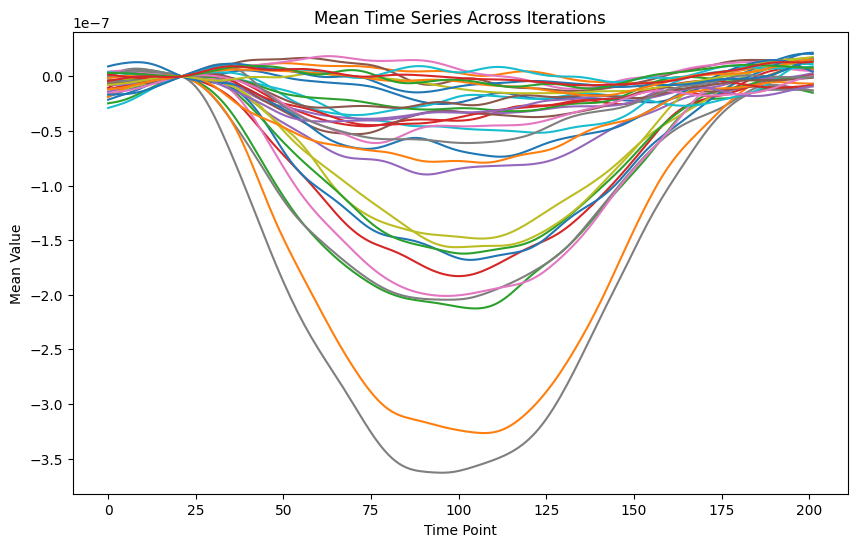

In [ ]:
# meanSeriesList = []

# for numChan in channels:

#     print(numChan)
    
#     # get functional data for this channel
#     dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)    
#     chanMean = np.mean(dataMatrix, axis = 0)
#     meanSeriesList.append(chanMean)

# plt.figure(figsize=(10, 6))
# for series in meanSeriesList:
#     plt.plot(series)

# plt.xlabel('Time Point')
# plt.ylabel('Mean Value')
# plt.title('Mean Time Series Across Iterations')
# plt.show()

In [12]:
for numChan in channels:
    
    # get functional data for this channel
    dataMatrix = fNIRSData.groupDataMatrix(dataFile, numChan, numChrom, firstTrial, lastTrial)                                      
    fd = skfda.FDataGrid(data_matrix=dataMatrix, grid_points=gridPoints)
    basis = BSplineBasis(n_basis=numBasis)
    fdObj = fd.to_basis(basis)
    
    #detect change points
    chanMat, pValues = (auxFuncChPt.findCPtsFF(fdObj, firstFunc, lastFunc, alphaVal = cptSignificance, h = lrCovLag, longRun = useLongRun, wildBinSeg = useWildBinSeg))
    chanMat = chanMat.astype('float32') #for downstream compatibility

    #within channel correction (multiple tests due to binseg approach)
    pAdjWithin = multipletests(pValues, alpha = cptSignificance, method=withinChanCorrectMethod)[1]  # within-channel multiple comparison correction (accounts for BinSeg)

    # initialise temporary channel dataframe rows
    tempRows = []
    #populate temp. dataframe with change point results
    for i in range(chanMat.shape[0]):
        tempRows.append({
            'Channel':numChan,
            'Chromophore':numChrom,
            'Recursion Level': (chanMat[i][4]),
            'First Trial':(chanMat[i][0]+1),
            'Last Trial': (chanMat[i][1]+1),
            'Change Point': (chanMat[i][2]+1),
            'Max. T_N': (chanMat[i][3]),
            'p-value': (chanMat[i][5]) 
        })
    # create temp. dataframe
    tempDf = pd.DataFrame(tempRows)
    if not tempDf.empty:
        tempDf.index = range(globalIndex, globalIndex + len(tempDf))

    filteredTempDf = auxFuncChPt.filterSignificantChanges(tempDf, cptSignificance, firstTrial, lastTrial)

    if not filteredTempDf.empty:

        #add filtered results to main dataframe
        dfChangePoints = pd.concat([dfChangePoints, filteredTempDf])

        #update global index
        globalIndex = dfChangePoints.index.max() + 1 if not dfChangePoints.empty else 0
        
    print('Progress: '+str(round((channels.index(numChan)+1) / len(channels) * 100, 1))+'%')

KeyboardInterrupt: 

In [30]:
#save the ChPt dataframe
with open(cptFilename, 'wb') as f:
    pickle.dump(dfChangePoints, f)

Again, if using more than one channel, group following 5 blocks inside a for loop i.e.:
<br>for numChan in channels:

In [31]:
"""
columnList = ['Channel',
'Final Change Point',
'Vol No Habituation',
'Vol Habituation',
'Ratio of Volumes']

dfVolumes = pd.DataFrame(columns = columnList)

#get list of only those channels in which a CPt has been detected (otherwise a volume calculation is pointless!)
cptChannels =np.unique(dfChangePoints["Channel"].values)

for numChan in cptChannels:
    
    dfChan = (dfChangePoints[dfChangePoints['Channel'] == numChan]).sort_values(by=['Change Point'])

    dataMatrix = fNIRSData.groupDataMatrix(dataFile,
                                        numChan,
                                        numChrom,
                                        firstTrial,
                                        lastTrial)

    changeColumn = (dfChan.get('Change Point').tolist())
    changeColumn = [int(x) for x in changeColumn]
    changeColumn.append(lastTrial + 1)

    iBlock = 0
    firstBlockTrial = 1
    blockMeans = np.empty([len(changeColumn), (abs(firstSamp)+abs(lastSamp))])
    
    for point in changeColumn:
        lastBlockTrial = point-1 #-1 because dataMatrix rows go from 0->(numTrials-1)
        blockMatrix = dataMatrix[firstBlockTrial-1:lastBlockTrial-1, ]
        blockMeans[iBlock] = np.mean(blockMatrix, axis = 0)
        firstBlockTrial = point
        iBlock = iBlock + 1

    changeColumn.insert(0,1)

    volNoHab = simpson(blockMeans[0, 21:], dx = 1) * lastTrial
    volHab = 0
    for i in range(0, len(changeColumn)-1):
        volTrial = (simpson(blockMeans[i, 21:], dx = 1)) * (changeColumn[i+1] - changeColumn[i])
        volHab = volHab + volTrial

    ratioHab = (volHab / volNoHab)

    dfVolumes = pd.concat([dfVolumes, pd.DataFrame.from_records([{
            'Channel':numChan,
            'Final Change Point':changeColumn[-2],
            'Vol No Habituation':abs(volNoHab),
            'Vol Habituation': abs(volHab),
            'Ratio of Volumes': ratioHab
            }])])
            """

'\ncolumnList = [\'Channel\',\n\'Final Change Point\',\n\'Vol No Habituation\',\n\'Vol Habituation\',\n\'Ratio of Volumes\']\n\ndfVolumes = pd.DataFrame(columns = columnList)\n\n#get list of only those channels in which a CPt has been detected (otherwise a volume calculation is pointless!)\ncptChannels =np.unique(dfChangePoints["Channel"].values)\n\nfor numChan in cptChannels:\n    \n    dfChan = (dfChangePoints[dfChangePoints[\'Channel\'] == numChan]).sort_values(by=[\'Change Point\'])\n\n    dataMatrix = fNIRSData.groupDataMatrix(dataFile,\n                                        numChan,\n                                        numChrom,\n                                        firstTrial,\n                                        lastTrial)\n\n    changeColumn = (dfChan.get(\'Change Point\').tolist())\n    changeColumn = [int(x) for x in changeColumn]\n    changeColumn.append(lastTrial + 1)\n\n    iBlock = 0\n    firstBlockTrial = 1\n    blockMeans = np.empty([len(changeColumn), (ab

In [32]:
"""
#save the Vol dataframe
with open(volFilename, 'wb') as f:
    pickle.dump(dfVolumes, f)
    """

"\n#save the Vol dataframe\nwith open(volFilename, 'wb') as f:\n    pickle.dump(dfVolumes, f)\n    "

In [33]:
"""
#plotting here works well on 12mo GM channel 3
trialFrame = pd.DataFrame(data=blockMeans)
trialFrame = trialFrame.T

trialFrame.plot()
"""

'\n#plotting here works well on 12mo GM channel 3\ntrialFrame = pd.DataFrame(data=blockMeans)\ntrialFrame = trialFrame.T\n\ntrialFrame.plot()\n'